### Stage 2: does a fine-tuned SmolLM2-135M on frozen TimeSformer clip tokens beat a linear probe?

Stage 1 passed: frozen TimeSformer (squash, layer 12) take features reach the gate. Stage 2 tests the proposed
model on the **score only**, against cheaper models that see the same features in the same folds:

* **SmolLM2-135M + LoRA**: each take's 1 s clips (CLS, patch mean, patch std at layer 12: 2304 numbers, standardized
  on the training takes) averaged into at most 128 time segments, mapped by a trained 2-layer projector into SmolLM's
  embedding space and placed in the prompt `Activity: <scenario>\nVideo: <segments>\nSkill level:`. The next-token
  logits of ` beginner / intermediate / advanced / expert` (one token each) give a 4-way softmax trained with
  cross-entropy. Trained: the projector and LoRA (r 16) on all attention and MLP projections; the rest is frozen.
* **Tiny transformer from scratch**: the same projector into 128 dimensions, a learned [CLS] plus scenario embedding,
  positional embeddings, 2 layers, 4 heads, the same 4-way head and loss. Tells whether the pretrained LM adds anything.
* **Ridge / logistic regression** on stage 1's take-level features (PCA-64 per block + scenario one-hot).
* **Duration only** (log seconds x scenario).

Neural models: AdamW, batch 16, up to 30 epochs; early stopping on the cross-entropy of a held-out 15% of the
training participants (patience 5), best epoch restored. Score = expected level under the softmax. Same 5-fold
participant splits and metric as before (predictions centered within fold and scenario, within-scenario Spearman with
level, participant bootstrap); N_REPEATS repeats of the folds, averaged.

**Gate (fixed before running)**: continue to stage 3 (adding proficiency.why) only if SmolLM reaches Spearman >= 0.35
and is not worse than the ridge on the same features by more than 0.03.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import gc
import math
import time

import torch
from scipy.stats import spearmanr
from tqdm.auto import tqdm

VARIANT, LAYER = "squash", 12
EMBEDDING_DIR = Path("embeddings")
all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
scenario_index = np.searchsorted(SCENARIO_NAMES, scenarios)
log_duration = np.log([clip_of[t]["seconds"] for t in names])

MAX_SEGMENTS = 128
ts = torch.load(EMBEDDING_DIR / "timesformer_k600_exo8fps_clips.pt")
li = {6: 0, 12: 1}[LAYER]
raw = [ts["clips"][VARIANT][t][:, li].float() for t in names]  # (n_clips, 3, 768)
del ts
gc.collect()

# Take-level features (stage 1's "all"): mean CLS, mean patch mean, mean token std, temporal std of the patch mean.
take_features = {
    "CLS": np.stack([x[:, 0].mean(0).numpy() for x in raw]),
    "mean": np.stack([x[:, 1].mean(0).numpy() for x in raw]),
    "token std": np.stack([x[:, 2].mean(0).numpy() for x in raw]),
    "temporal std": np.stack([x[:, 1].std(0).numpy() if len(x) > 1 else np.zeros(768, np.float32) for x in raw]),
}

def segments(x):
    """(n_clips, 3, 768) -> (<= MAX_SEGMENTS, 2304): clips averaged into equal time bins when the take is longer."""
    x = x.reshape(len(x), -1)
    if len(x) <= MAX_SEGMENTS:
        return x
    edges = np.linspace(0, len(x), MAX_SEGMENTS + 1).round().astype(int)
    return torch.stack([x[a:b].mean(0) for a, b in zip(edges[:-1], edges[1:])])

sequences = [segments(x) for x in raw]
lengths = np.array([len(s) for s in sequences])
del raw
gc.collect()
print(f"{len(names)} takes; segments per take median {np.median(lengths):.0f}, max {lengths.max()}, "
      f"{(lengths == MAX_SEGMENTS).mean():.0%} capped; levels {dict(sorted(Counter(scores).items()))}")

1338 takes; segments per take median 56, max 128, 22% capped; levels {np.int64(1): 135, np.int64(2): 361, np.int64(3): 419, np.int64(4): 423}


In [3]:
import torch.nn as nn
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model
from sklearn.model_selection import GroupShuffleSplit
from transformers import AutoModelForCausalLM, AutoTokenizer

SMOL = "HuggingFaceTB/SmolLM2-135M"
DEVICE = "cuda"
LEVEL_WORDS = [" beginner", " intermediate", " advanced", " expert"]
tokenizer = AutoTokenizer.from_pretrained(SMOL)
LEVEL_IDS = [tokenizer.encode(w)[0] for w in LEVEL_WORDS]
assert all(len(tokenizer.encode(w)) == 1 for w in LEVEL_WORDS), "level words must be single tokens"
PREFIX_IDS = [tokenizer.encode(f"Activity: {s}\nVideo:") for s in SCENARIO_NAMES]
SUFFIX_IDS = tokenizer.encode("\nSkill level:")
D_IN = sequences[0].shape[-1]

def projector(d_out):
    return nn.Sequential(nn.LayerNorm(D_IN), nn.Linear(D_IN, d_out), nn.GELU(), nn.Linear(d_out, d_out))

class SmolVideo(nn.Module):
    def __init__(self):
        super().__init__()
        lm = AutoModelForCausalLM.from_pretrained(SMOL, torch_dtype=torch.float32)
        self.lm = get_peft_model(lm, LoraConfig(
            r=16, lora_alpha=32, lora_dropout=0.05,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
        d = lm.config.hidden_size
        self.proj = projector(d)
        self.scale = nn.Parameter(self.embed_table().weight.detach().std() * torch.ones(1))  # token-embedding scale

    def embed_table(self):
        return self.lm.get_input_embeddings()

    def embed(self, ids):
        return self.embed_table()(ids)

    def forward(self, x, mask, scenario):
        """x (B, S, D_IN) padded, mask (B, S) bool, scenario (B,) -> (B, 4) level logits."""
        video = self.proj(x) * self.scale
        rows, lasts = [], []
        for b in range(len(x)):
            prefix = self.embed(torch.tensor(PREFIX_IDS[scenario[b]], device=x.device))
            suffix = self.embed(torch.tensor(SUFFIX_IDS, device=x.device))
            row = torch.cat([prefix, video[b, mask[b]], suffix])
            rows.append(row)
            lasts.append(len(row) - 1)
        width = max(len(r) for r in rows)
        inputs = torch.stack([F.pad(r, (0, 0, 0, width - len(r))) for r in rows])
        attention = torch.stack([torch.arange(width, device=x.device) <= l for l in lasts]).long()
        with torch.autocast("cuda", dtype=torch.bfloat16):
            hidden = self.lm(inputs_embeds=inputs, attention_mask=attention).logits  # right padding: causal, unaffected
        last = hidden[torch.arange(len(x)), torch.tensor(lasts, device=x.device)]
        return last[:, LEVEL_IDS].float()

class TinyTransformer(nn.Module):
    def __init__(self, d=128):
        super().__init__()
        self.proj = projector(d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.scenario = nn.Embedding(len(SCENARIO_NAMES), d)
        self.pos = nn.Parameter(0.02 * torch.randn(1, MAX_SEGMENTS + 1, d))
        layer = nn.TransformerEncoderLayer(d, 4, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, 2)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4))

    def forward(self, x, mask, scenario):
        h = self.proj(x)
        cls = self.cls.expand(len(x), -1, -1) + self.scenario(scenario)[:, None]
        h = torch.cat([cls, h], 1) + self.pos[:, : h.shape[1] + 1]
        pad = torch.cat([torch.zeros(len(x), 1, dtype=torch.bool, device=x.device), ~mask], 1)
        return self.head(self.encoder(h, src_key_padding_mask=pad)[:, 0])

LR = {"SmolLM2-135M + LoRA": {"proj": 1e-3, "rest": 2e-4}, "tiny transformer": {"proj": 1e-3, "rest": 1e-3}}
BUILD = {"SmolLM2-135M + LoRA": SmolVideo, "tiny transformer": TinyTransformer}
BATCH, MAX_EPOCHS, PATIENCE, VAL_FRACTION = 16, 30, 5, 0.15

def batch_of(rows, normalize):
    x = torch.zeros(len(rows), lengths[rows].max(), D_IN)
    mask = torch.zeros(len(rows), lengths[rows].max(), dtype=torch.bool)
    for i, r in enumerate(rows):
        x[i, : lengths[r]] = sequences[r]
        mask[i, : lengths[r]] = True
    x = normalize(x)
    return (x.to(DEVICE), mask.to(DEVICE), torch.tensor(scenario_index[rows], device=DEVICE),
            torch.tensor(scores[rows] - 1, device=DEVICE))

@torch.no_grad()
def predict(model, rows, normalize):
    model.eval()
    out = []
    for i in range(0, len(rows), 32):
        x, mask, s, _ = batch_of(rows[i:i + 32], normalize)
        out.append(torch.softmax(model(x, mask, s), -1).cpu())
    return torch.cat(out).numpy()

def train(name, fit, seed):
    """Train on `fit` (indices) with early stopping on a participant-held-out 15%. Returns (model, normalize, log)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    inner, val = next(GroupShuffleSplit(1, test_size=VAL_FRACTION, random_state=seed).split(fit, groups=participants[fit]))
    inner, val = fit[inner], fit[val]
    stacked = torch.cat([sequences[r] for r in inner])
    mu, sd = stacked.mean(0), stacked.std(0).clamp_min(1e-4)
    normalize = lambda x: (x - mu) / sd
    model = BUILD[name]().to(DEVICE)
    proj = [p for n, p in model.named_parameters() if p.requires_grad and (n.startswith("proj") or n == "scale")]
    rest = [p for n, p in model.named_parameters() if p.requires_grad and not (n.startswith("proj") or n == "scale")]
    optimizer = torch.optim.AdamW([{"params": proj, "lr": LR[name]["proj"]}, {"params": rest, "lr": LR[name]["rest"]}],
                                  weight_decay=0.01)
    steps = MAX_EPOCHS * math.ceil(len(inner) / BATCH)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[LR[name]["proj"], LR[name]["rest"]],
                                                   total_steps=steps, pct_start=0.1)
    best, best_state, since, log = np.inf, None, 0, []
    for epoch in range(MAX_EPOCHS):
        model.train()
        order = rng.permutation(inner)
        for i in range(0, len(order), BATCH):
            x, mask, s, y = batch_of(order[i:i + BATCH], normalize)
            loss = F.cross_entropy(model(x, mask, s), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            schedule.step()
        p = predict(model, val, normalize)
        val_loss = -np.log(p[np.arange(len(val)), scores[val] - 1] + 1e-9).mean()
        log.append(val_loss)
        if val_loss < best - 1e-4:
            best, since = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if "lm.base_model" not in k or "lora" in k}
        else:
            since += 1
            if since >= PATIENCE:
                break
    model.load_state_dict(best_state, strict=False)
    return model, normalize, log

W1116 17:55:37.477000 39528 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [4]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS = 2, 5, 64
NEURAL = ["SmolLM2-135M + LoRA", "tiny transformer"]

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
fold_of = np.zeros((N_REPEATS, len(names)), int)
logs = defaultdict(list)
t0 = time.time()
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def linear(key, X_features):
            X = np.hstack([onehot, X_features])
            probe = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
            hits[key][repeat, held] = probe.fit(X[fit], scores[fit]).predict(X[held]) == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        linear("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        linear("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))
        blocks = [PCA(PCA_DIMS, svd_solver="full").fit(centered(X, scenarios, fit)[fit]).transform(centered(X, scenarios, fit))
                  for X in take_features.values()]
        linear("linear probe (stage 1 features)", np.hstack(blocks))

        for name in NEURAL:
            model, normalize, log = train(name, fit, seed=100 * repeat + fold)
            p = predict(model, held, normalize)
            hits[name][repeat, held] = p.argmax(1) + 1 == scores[held]
            continuous[name][repeat, held] = p @ np.arange(1, 5)
            logs[name].append(log)
            print(f"repeat {repeat + 1} fold {fold + 1} {name:<22} epochs {len(log):>2} (best {int(np.argmin(log)) + 1:>2}) "
                  f"val CE {min(log):.3f}  [{(time.time() - t0) / 60:.1f} min]")
            del model
            torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

repeat 1 fold 1 SmolLM2-135M + LoRA    epochs  6 (best  1) val CE 1.424  [1.5 min]


C:\Users\darkn\AppData\Local\Temp\ipykernel_39528\4120170218.py:63: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, 2)


repeat 1 fold 1 tiny transformer       epochs  7 (best  2) val CE 1.593  [1.6 min]


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

... (31 outputs left out)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

repeat 2 fold 5 SmolLM2-135M + LoRA    epochs  7 (best  2) val CE 1.432  [20.3 min]


C:\Users\darkn\AppData\Local\Temp\ipykernel_39528\4120170218.py:63: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, 2)


repeat 2 fold 5 tiny transformer       epochs  6 (best  1) val CE 1.676  [20.4 min]


In [5]:
N_BOOTSTRAP = 500
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]

def scenario_centered(values):
    out = values.astype(float).copy()
    for s in SCENARIO_NAMES:
        out[scenarios == s] -= values[scenarios == s].mean()
    return out

level_centered = scenario_centered(scores)

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}
per_take = {key: h.mean(0) for key, h in hits.items()}

def rho(key, rows):
    a = ordinal[key][rows]
    return spearmanr(a, level_centered[rows])[0] if np.std(a) > 1e-9 else 0.0

ALL = np.ones(len(names), bool)
spearman = {key: (rho(key, ALL), *np.quantile([rho(key, r) for r in resamples], [0.025, 0.975])) for key in ordinal}
KEYS = ["scenario only", "duration only", "linear probe (stage 1 features)", *NEURAL]
print(f"{'model':<36}{'Spearman with level':>28}{'accuracy':>26}")
for key in KEYS:
    s = spearman[key]
    a = per_take[key].mean(), *np.quantile([per_take[key][r].mean() for r in resamples], [0.025, 0.975])
    print(f"{key:<36}{s[0]:>+10.3f} [{s[1]:+.3f}, {s[2]:+.3f}]{a[0]:>10.3f} [{a[1]:.3f}, {a[2]:.3f}]")

def difference(a, b):
    d = np.array([rho(a, r) - rho(b, r) for r in resamples])
    return spearman[a][0] - spearman[b][0], *np.quantile(d, [0.025, 0.975])

for a, b in [("SmolLM2-135M + LoRA", "linear probe (stage 1 features)"), ("SmolLM2-135M + LoRA", "tiny transformer"),
             ("tiny transformer", "linear probe (stage 1 features)")]:
    d = difference(a, b)
    print(f"{a} minus {b}: {d[0]:+.3f} [{d[1]:+.3f}, {d[2]:+.3f}]")

GATE, MARGIN = 0.35, 0.03
smol, ridge = spearman["SmolLM2-135M + LoRA"][0], spearman["linear probe (stage 1 features)"][0]
passed = smol >= GATE and smol >= ridge - MARGIN
print(f"\nGATE (SmolLM Spearman >= {GATE} and >= linear probe - {MARGIN}): {smol:+.3f} vs {ridge:+.3f} -> "
      f"{'PASS' if passed else 'FAIL'}")

print(f"\n{'per scenario':<36}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
for key in KEYS[1:]:
    print(f"{key:<36}" + "".join(f"{rho(key, scenarios == s):>+18.2f}" for s in SCENARIO_NAMES))
for name in NEURAL:
    print(f"{name}: epochs to best {[int(np.argmin(l)) + 1 for l in logs[name]]}")

model                                        Spearman with level                  accuracy
scenario only                           +0.000 [+0.000, +0.000]     0.389 [0.316, 0.466]
duration only                           +0.248 [+0.151, +0.337]     0.393 [0.333, 0.455]
linear probe (stage 1 features)         +0.422 [+0.274, +0.531]     0.436 [0.375, 0.503]
SmolLM2-135M + LoRA                     +0.295 [+0.173, +0.417]     0.381 [0.331, 0.445]
tiny transformer                        +0.355 [+0.224, +0.467]     0.405 [0.339, 0.477]


SmolLM2-135M + LoRA minus linear probe (stage 1 features): -0.127 [-0.260, +0.012]


SmolLM2-135M + LoRA minus tiny transformer: -0.059 [-0.191, +0.086]
tiny transformer minus linear probe (stage 1 features): -0.068 [-0.143, +0.005]

GATE (SmolLM Spearman >= 0.35 and >= linear probe - 0.03): +0.295 vs +0.422 -> FAIL

per scenario                          Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)


duration only                                    +0.22             +0.46             +0.26             -0.05             +0.30             -0.23
linear probe (stage 1 features)                  +0.52             +0.20             +0.20             -0.17             +0.66             +0.24
SmolLM2-135M + LoRA                              +0.45             -0.05             +0.08             -0.13             +0.48             +0.51
tiny transformer                                 +0.38             +0.28             +0.23             -0.31             +0.49             +0.34
SmolLM2-135M + LoRA: epochs to best [1, 3, 1, 4, 5, 4, 7, 2, 1, 2]
tiny transformer: epochs to best [2, 1, 4, 1, 2, 1, 1, 2, 1, 1]


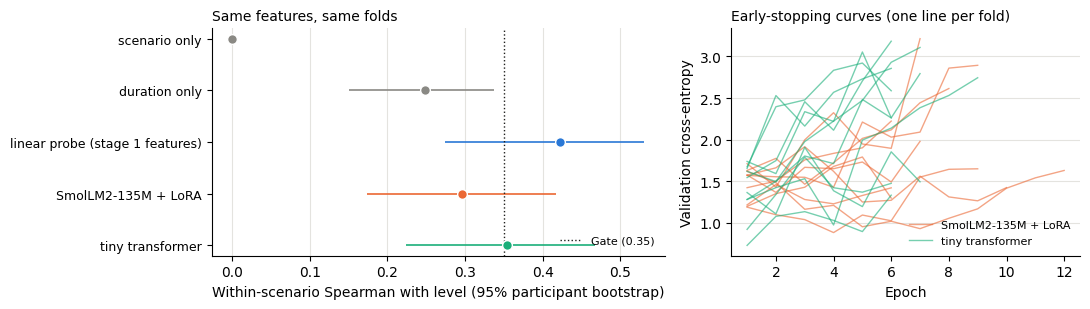

In [6]:
import matplotlib.pyplot as plt

GRID_COLOR, DARK, GRAY = "#e4e3df", "#1f1f1d", "#8a8984"
COLOR = {"scenario only": GRAY, "duration only": GRAY, "linear probe (stage 1 features)": "#2a78d6",
         "tiny transformer": "#1baf7a", "SmolLM2-135M + LoRA": "#eb6834"}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.3, 1]})
y = np.arange(len(KEYS))[::-1]
for yy, key in zip(y, KEYS):
    s = spearman[key]
    ax.errorbar(s[0], yy, xerr=[[s[0] - s[1]], [s[2] - s[0]]], fmt="o", ms=7, color=COLOR[key],
                markeredgecolor="white", markeredgewidth=1, elinewidth=1.2)
ax.axvline(GATE, color=DARK, lw=1, ls=":", label=f"Gate ({GATE})")
ax.set_yticks(y, KEYS, fontsize=9)
ax.set_xlabel("Within-scenario Spearman with level (95% participant bootstrap)")
ax.set_title("Same features, same folds", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
for name in NEURAL:
    for i, l in enumerate(logs[name]):
        bx.plot(np.arange(1, len(l) + 1), l, color=COLOR[name], lw=1, alpha=0.6, label=name if i == 0 else None)
bx.set_xlabel("Epoch")
bx.set_ylabel("Validation cross-entropy")
bx.set_title("Early-stopping curves (one line per fold)", loc="left", fontsize=10)
bx.legend(frameon=False, fontsize=8)
for a in (ax, bx):
    a.grid(axis="x" if a is ax else "y", color=GRID_COLOR, lw=0.8)
    a.set_axisbelow(True)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig("figures/smollm_stage2.png", dpi=200, bbox_inches="tight")
plt.show()